# Lluvia de 6 h con la que se emitieron declaratorias asociadas a CT: percentil local, mapas e intervalos

Sustituye a `declaratorias_6h_exploracion`, `declaratorias_6h_pixel_municipio` y `declaratorias_6h_por_tipo`. Usa las salidas de `scripts/declaratorias_6h.py` (`outputs/diagnostics/declaratorias_6h/`) y los percentiles de 6 h de MSWEP V3.16 (`mswep_v3_6h_percentiles_may_nov.nc`: P75, P90, P95, P99, P99.9).

**Definiciones**

- **P6**: acumulado de MSWEP V3.16 en $(T-6\,\mathrm{h},\,T]$, con $T$ = 00/06/12/18 UTC y un CT activo durante la declaratoria.
- **Por píxel**: para cada declaratoria, el máximo de P6 en el píxel (`P6_pix`). Entre declaratorias: mínimo, media, mediana y máximo.
- **Por municipio**: $P_{\mathrm{evento}}$ es el máximo de P6 sobre los píxeles del municipio y los pasos de la declaratoria; se compara con los percentiles de ese mismo píxel.
- **Percentil equivalente** $r(P)$: el nivel de no excedencia local que corresponde a $P$ (sección 2), y su **clase**: < P75, P75–P90, P90–P95, P95–P99, P99–P99.9, ≥ P99.9.
- **Diferencia** $P - P_{95}$ (mm (6 h)⁻¹): negativa significa que la declaratoria se emitió con lluvia menor que el P95 local.

**Tipos**: *Emergencia* es preventiva y puede emitirse antes de la lluvia; *Desastre* se emite tras verificar daños; *Contingencia climatológica* corresponde a daños agropecuarios. Para umbrales de decisión, el tipo relevante es Desastre (sección 6).

**Paletas** (mismas convenciones que ITCHI): lluvia en mm con `lapaz` invertida de Crameri (perceptualmente uniforme, clara = poca lluvia); diferencia respecto al percentil con `BrBG` divergente (café = por debajo, verde azulado = por arriba); clase de percentil con los colores SIAT de `itchi.plotting` (gris, azul, verde, amarillo, naranja, rojo).

## 1. Lectura

In [27]:
import sys
from pathlib import Path

import cartopy.crs as ccrs
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import BoundaryNorm, ListedColormap

from itchi.plotting import SIAT_DANGER_COLORS, MapStyle, configure_map_axis, get_crameri_colormap

REPO =  Path("/mnt/c/Users/adolf/Documents/ITCHI/itchi-core")
sys.path.insert(0, str(REPO / "scripts"))

from itchi.declaratorias_6h import Config, run  # noqa: E402

cfg = Config()
OUT = REPO / "outputs/diagnostics/declaratorias_6h"
FIG = REPO / "outputs/figures/declaratorias_6h_sintesis"
FIG.mkdir(parents=True, exist_ok=True)

RUN = not (OUT / "declaratorias_ct_eventos.csv").exists()    # True recalcula (lee D:/MSWEP_V316_6H)
if RUN:
    run(cfg)

In [28]:
# Parámetros de análisis
TIPO_MAPA = "Desastre"          # "todas", "Emergencia", "Desastre", "Contingencia Climatológica"
TIPO_INT = "Desastre"        # tipo para los intervalos de decisión (sección 6)
N_MIN = 1                    # declaratorias mínimas para mostrar un municipio en los mapas
N_MIN_INT = 5                # declaratorias mínimas para un intervalo municipal
EXCLUIR_NO_ESPECIFICA = False   # "No se especifican los municipios afectados" (p. ej. TT Rosa 2000)
PCT_VAR = "p_wet"               # variable de percentiles en el NetCDF; None = detección automática
TIPOS = ["Emergencia", "Desastre", "Contingencia Climatológica"]

ev = pd.read_csv(OUT / "declaratorias_ct_eventos.csv", dtype={"CVEGEO": str},
                 parse_dates=["t_pico", "fecha_inicio", "fecha_fin"])
pdcl = pd.read_csv(OUT / "declaratorias_ct_pixel_decl.csv.gz", dtype={"CVEGEO": str},
                   parse_dates=["t_max_pix"])
ps = xr.open_dataset(OUT / "declaratorias_ct_pixel_stats.nc")

ev = ev[ev["P_evento"].notna()].copy()
ev["no_especifica"] = ev["Observaciones"].str.lower().str.contains("no se especifica", na=False)
if EXCLUIR_NO_ESPECIFICA:
    ev = ev[~ev["no_especifica"]]
    pdcl = pdcl[pdcl["id_decl"].isin(ev["id_decl"])]

gdf_mun = gpd.read_file(cfg.mun_shp, encoding=getattr(cfg, "shp_encoding", "utf-8"))
gdf_mun["CVEGEO"] = gdf_mun["CVEGEO"].astype(str).str.zfill(5)
estados = gdf_mun.dissolve(by="CVE_ENT")

LABS = [c.replace("dif_", "") for c in ev.columns if c.startswith("dif_")]   # P75 ... P99_9
LEVELS = np.array([float(l[1:].replace("_", ".")) for l in LABS])            # 75 ... 99.9
print(f"Declaratorias: {len(ev):,} | municipios: {ev['CVEGEO'].nunique():,} | "
      f"píxeles: {pdcl['ipix'].nunique():,} | percentiles: {LABS}")
ev["Tipo Declaratoria"].value_counts()

Declaratorias: 10,437 | municipios: 1,712 | píxeles: 11,497 | percentiles: ['P75', 'P90', 'P95', 'P99', 'P99_9']


Tipo Declaratoria
Emergencia                    5794
Desastre                      4388
Contingencia Climatológica     255
Name: count, dtype: int64

In [29]:
# Percentiles locales de 6 h en la malla de las estadísticas por píxel
pct_ds = xr.open_dataset(cfg.percentiles_file)
cands = [v for v in pct_ds.data_vars if any(d in pct_ds[v].dims for d in ("quantile", "percentile"))]
var = PCT_VAR or (cands[0] if len(cands) == 1 else None)
assert var is not None, f"varias variables de percentiles {cands}: fija PCT_VAR a la que usa declaratorias_6h.py"
qdim = next(d for d in ("quantile", "percentile") if d in pct_ds[var].dims)
lv = np.asarray(pct_ds[qdim].values, dtype=float)
lv = lv * 100 if lv.max() <= 1 else lv
pct = pct_ds[var].assign_coords({qdim: lv}).sel({qdim: LEVELS}, method="nearest")
pct = pct.rename({d: {"latitude": "lat", "longitude": "lon"}[d]
                  for d in pct.dims if d in ("latitude", "longitude")})
QPIX = pct.reindex(lat=ps["lat"], lon=ps["lon"], method="nearest", tolerance=1e-3) \
          .transpose(qdim, "lat", "lon").values                                  # (nivel, lat, lon)

# Control: el percentil leído coincide con el que usó el script en el píxel del máximo
imax = pdcl.loc[pdcl.groupby("id_decl")["P6_pix"].idxmax(), ["id_decl", "lat", "lon"]]
j = np.abs(ps["lat"].values[None, :] - imax["lat"].values[:, None]).argmin(1)
i = np.abs(ps["lon"].values[None, :] - imax["lon"].values[:, None]).argmin(1)
k95 = LABS.index("P95")
chk = imax.assign(q95=QPIX[k95, j, i]).merge(ev[["id_decl", "P95_pixel_max"]], on="id_decl")
print(f"variable {var!r} | |Q95 leído − Q95 del script|: mediana "
      f"{(chk['q95'] - chk['P95_pixel_max']).abs().median():.3f} mm")

variable 'p_wet' | |Q95 leído − Q95 del script|: mediana 0.000 mm


## 2. Percentil equivalente y clases

Con los niveles $L = (75, 90, 95, 99, 99.9)$ y los percentiles locales $Q_{L_k}$ del píxel, el percentil equivalente se obtiene interpolando linealmente la función de distribución entre percentiles conocidos:

$$
r(P) = L_k + (L_{k+1} - L_k)\,\frac{P - Q_{L_k}}{Q_{L_{k+1}} - Q_{L_k}}, \qquad Q_{L_k} \le P < Q_{L_{k+1}}
$$

Por debajo de $Q_{75}$ y por encima de $Q_{99.9}$ el valor está censurado: solo se sabe que es "< P75" o "≥ P99.9". La clase es el número de percentiles superados, $c(P) = \#\{k : P \ge Q_{L_k}\} \in \{0,\dots,5\}$. La inversa, $Q(r)$, convierte un percentil equivalente en mm para cualquier píxel (sección 6, método C).

La interpolación lineal entre percentiles es una aproximación: la distribución real de P6 tiene cola larga, de modo que $r$ es ligeramente sesgado hacia arriba dentro de cada tramo; la clase no depende de esta aproximación.

In [30]:
EPS = 1e-6
CLASS_LABELS = ["< P75", "P75–P90", "P90–P95", "P95–P99", "P99–P99.9", "≥ P99.9"]


def pct_class(p, q):
    # Número de percentiles superados (0..5); q con forma (nivel, ...)
    p = np.asarray(p, dtype=float)
    c = np.sum(p[None] >= q, axis=0).astype(float)
    return np.where(np.isfinite(p) & np.all(np.isfinite(q), axis=0), c, np.nan)


def pct_equiv(p, q):
    # Percentil equivalente; < P75 -> NaN (censurado), >= P99.9 -> 99.9
    p = np.asarray(p, dtype=float)
    r = np.full(np.broadcast(p, q[0]).shape, np.nan)
    for k in range(len(LEVELS) - 1):
        seg = (p >= q[k]) & (p < q[k + 1])
        f = (p - q[k]) / np.maximum(q[k + 1] - q[k], EPS)
        r = np.where(seg, LEVELS[k] + (LEVELS[k + 1] - LEVELS[k]) * f, r)
    return np.where(p >= q[-1], LEVELS[-1], r)


def pct_to_mm(r, q):
    # Inversa: mm locales para un percentil equivalente r en [75, 99.9]
    k = np.clip(np.searchsorted(LEVELS, r, side="right") - 1, 0, len(LEVELS) - 2)
    f = (r - LEVELS[k]) / (LEVELS[k + 1] - LEVELS[k])
    return q[k] + (q[k + 1] - q[k]) * f if LEVELS[0] <= r <= LEVELS[-1] else np.full(q[0].shape, np.nan)


# Por declaratoria, con los percentiles del píxel donde ocurrió su máximo
Q_EV = ev[[f"{l}_pixel_max" for l in LABS]].to_numpy().T
ev["clase"] = pct_class(ev["P_evento"].to_numpy(), Q_EV)
ev["r_equiv"] = pct_equiv(ev["P_evento"].to_numpy(), Q_EV)
# Orden total con censura: < P75 -> 0, para cuantiles de r
ev["r_ord"] = np.where(ev["clase"] == 0, 0.0, ev["r_equiv"])

# Verificación con un píxel sintético
q_t = np.array([2.0, 6.0, 10.0, 22.0, 40.0])[:, None]
assert pct_class(np.array([1.0, 6.0, 30.0, 50.0]), q_t).tolist() == [0, 2, 4, 5]
assert np.allclose(pct_equiv(np.array([8.0]), q_t), 92.5)
assert np.allclose(pct_to_mm(92.5, q_t), 8.0)
print("funciones de percentil: OK")

funciones de percentil: OK


## 3. Resumen por tipo de declaratoria

In [31]:
def resumen(g):
    r = {"n": len(g), "municipios": g["CVEGEO"].nunique(),
         "% < 1 mm": 100 * (g["P_evento"] < 1).mean(),
         "P_evento P10": g["P_evento"].quantile(0.10), "P_evento mediana": g["P_evento"].median(),
         "percentil equiv. mediano": np.quantile(g["r_ord"].dropna(), 0.5, method="lower"),
         "% dentro ROCLOUD": 100 * (g["dentro_rocloud_pico"] == True).mean()}   # noqa: E712
    r.update({f"% < {l}": 100 * (g[f"dif_{l}"] < 0).mean() for l in LABS})
    r.update({f"dif {l} mediana": g[f"dif_{l}"].median() for l in ("P75", "P95")})
    return pd.Series(r)


tabla_tipo = pd.concat({t: resumen(ev[ev["Tipo Declaratoria"].eq(t)]) for t in TIPOS}
                       | {"todas": resumen(ev)}, axis=1).T.astype(float)
tabla_tipo.to_csv(FIG / "resumen_por_tipo.csv", float_format="%.2f")

# Misma tormenta y mismo municipio: Emergencia frente a Desastre
k = ["CVEGEO", "CT_pico"]
pares = pd.concat({t: ev[ev["Tipo Declaratoria"].eq(t)].groupby(k)["P_evento"].max()
                   for t in ("Emergencia", "Desastre")}, axis=1).dropna()
d = pares["Emergencia"] - pares["Desastre"]
print(f"Pares municipio–CT con ambos tipos: {len(pares):,} | Emergencia < Desastre: {100 * (d < 0).mean():.1f} % "
      f"| iguales: {100 * (d.abs() < 0.01).mean():.1f} %")
tabla_tipo.round(1)

Pares municipio–CT con ambos tipos: 2,555 | Emergencia < Desastre: 27.0 % | iguales: 70.9 %


,n,municipios,% < 1 mm,P_evento P10,P_evento mediana,percentil equiv. mediano,% dentro ROCLOUD,% < P75,% < P90,% < P95,% < P99,% < P99_9,dif P75 mediana,dif P95 mediana
Emergencia,5794.0,1625.0,18.0,0.2,25.7,92.5,78.8,37.5,46.7,53.2,71.5,91.9,14.6,-4.5
Desastre,4388.0,1482.0,0.9,19.8,61.8,99.2,89.5,3.8,8.5,15.0,41.0,82.2,50.7,30.8
Contingencia Climatológica,255.0,219.0,0.0,29.6,64.7,99.6,94.5,1.2,5.5,10.6,25.9,61.2,54.1,38.1
todas,10437.0,1712.0,10.4,0.9,45.9,97.7,83.7,22.4,29.6,36.1,57.5,87.1,34.7,15.1


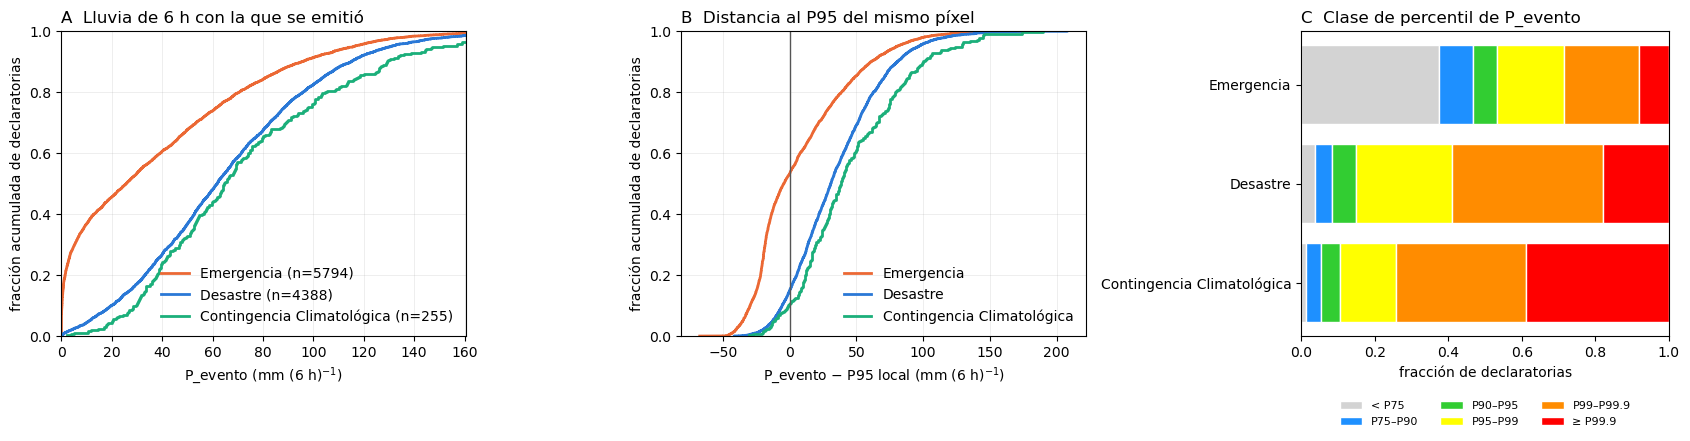

In [32]:
COL = dict(zip(TIPOS, ["#eb6834", "#2a78d6", "#1baf7a"]))    # identidad por tipo, orden fijo


def ecdf(ax, x, **kw):
    x = np.sort(np.asarray(x, dtype=float))
    x = x[np.isfinite(x)]
    ax.step(x, np.arange(1, x.size + 1) / x.size, where="post", lw=2, **kw)


fig, axs = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.1, 1.1, 1.0]})
for t in TIPOS:
    g = ev[ev["Tipo Declaratoria"].eq(t)]
    ecdf(axs[0], g["P_evento"], color=COL[t], label=f"{t} (n={len(g)})")
    ecdf(axs[1], g["dif_P95"], color=COL[t], label=t)
axs[0].set(xlim=(0, np.nanpercentile(ev["P_evento"], 99)), xlabel="P_evento (mm (6 h)$^{-1}$)")
axs[0].set_title("A  Lluvia de 6 h con la que se emitió", loc="left")
axs[1].axvline(0, color="#555555", lw=1)
axs[1].set_xlabel("P_evento − P95 local (mm (6 h)$^{-1}$)")
axs[1].set_title("B  Distancia al P95 del mismo píxel", loc="left")
for ax in axs[:2]:
    ax.set(ylabel="fracción acumulada de declaratorias", ylim=(0, 1))
    ax.grid(alpha=0.3, lw=0.5)
    ax.legend(frameon=False, loc="lower right")

# C: distribución de la clase de percentil por tipo (barras apiladas, colores SIAT)
frac = pd.crosstab(ev["Tipo Declaratoria"], ev["clase"].fillna(-1).astype(int), normalize="index").reindex(TIPOS) \
         .reindex(columns=range(6), fill_value=0)
left = np.zeros(len(TIPOS))
for c in range(6):
    axs[2].barh(TIPOS, frac[c], left=left, color=SIAT_DANGER_COLORS[c], edgecolor="white",
                label=CLASS_LABELS[c])
    left += frac[c].to_numpy()
axs[2].set(xlim=(0, 1), xlabel="fracción de declaratorias")
axs[2].invert_yaxis()
axs[2].legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
axs[2].set_title("C  Clase de percentil de P_evento", loc="left")
fig.tight_layout()
fig.savefig(FIG / "fig_tipos_distribuciones.png", dpi=300, bbox_inches="tight")

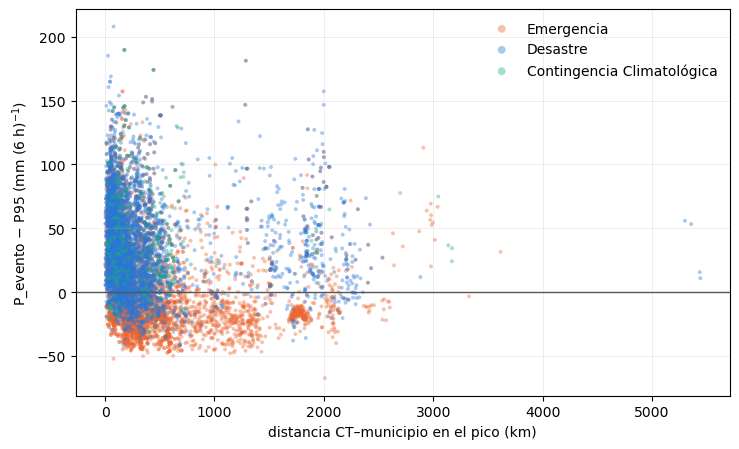

In [33]:
# ¿El CT estaba cerca? Diferencia al P95 contra distancia CT–municipio en el pico
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for t in TIPOS:
    g = ev[ev["Tipo Declaratoria"].eq(t)]
    ax.scatter(g["dist_pico_km"], g["dif_P95"], s=8, color=COL[t], alpha=0.4, edgecolor="none", label=t)
ax.axhline(0, color="#555555", lw=1)
ax.set(xlabel="distancia CT–municipio en el pico (km)", ylabel="P_evento − P95 (mm (6 h)$^{-1}$)")
ax.grid(alpha=0.3, lw=0.5)
ax.legend(frameon=False, markerscale=2)
fig.tight_layout()
fig.savefig(FIG / "fig_dif_P95_vs_distancia.png", dpi=300, bbox_inches="tight")

## 4. Mapas por píxel: lluvia mínima y media entre declaratorias, su clase de percentil y su diferencia con el P95

Filas: mínimo y media, entre declaratorias, del máximo de 6 h en el píxel. Columnas: mm, clase de percentil local y $P - P_{95}$. El mínimo dice con cuánta lluvia, como mínimo, ha habido declaratorias en ese píxel; la media, con cuánta lluvia típicamente.

In [34]:
PC = ccrs.PlateCarree()
STYLE = MapStyle(lon_extent=(-118.0, -86.0), lat_extent=(14.0, 34.0), lon_tick_spacing=8.0,
                 lat_tick_spacing=5.0, grid_spacing=4.0, label_size=9.0, tick_size=4.0,
                 coastline_linewidth=0.7, border_linewidth=0.6, land_color="white", land_alpha=1.0)

# Lluvia (mm): lapaz invertida de Crameri en clases
B_P = [0, 1, 5, 10, 20, 30, 40, 50, 60, 80, 100, 150]
try:
    _base_p = get_crameri_colormap("lapaz", reverse=True)
except ImportError:
    _base_p = plt.cm.YlGnBu
CMAP_P = ListedColormap(_base_p(np.linspace(0.08, 1.0, len(B_P))))
NORM_P = BoundaryNorm(B_P, CMAP_P.N, extend="max")

# Diferencia (mm): BrBG, café = por debajo del percentil
B_D = [-60, -40, -20, -10, -5, 0, 5, 10, 20, 40, 60]
CMAP_D = ListedColormap(plt.cm.BrBG(np.linspace(0.05, 0.95, len(B_D) + 1)))
NORM_D = BoundaryNorm(B_D, CMAP_D.N, extend="both")

# Clase de percentil: colores SIAT de ITCHI
CMAP_C = ListedColormap(SIAT_DANGER_COLORS)
NORM_C = BoundaryNorm(np.arange(-0.5, 6.5, 1.0), CMAP_C.N)

KINDS = {
    "P": dict(cmap=CMAP_P, norm=NORM_P, ticks=B_P, label="mm (6 h)$^{-1}$"),
    "C": dict(cmap=CMAP_C, norm=NORM_C, ticks=range(6), ticklabels=CLASS_LABELS, label="clase de percentil local"),
    "D": dict(cmap=CMAP_D, norm=NORM_D, ticks=B_D, label="P − P95 local (mm (6 h)$^{-1}$)"),
}


def finish_map(ax, title):
    estados.boundary.plot(ax=ax, color="#444444", lw=0.4, zorder=5, aspect=None)
    configure_map_axis(ax, crs=PC, style=STYLE)
    ax.set_title(title, loc="left", fontsize=10)


def add_cbar(fig, ax, kind, label=None):
    k = KINDS[kind]
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=k["norm"], cmap=k["cmap"]), ax=ax,
                      orientation="horizontal", shrink=0.85, pad=0.07, aspect=30, ticks=k["ticks"])
    cb.set_label(label or k["label"], fontsize=9)
    cb.ax.tick_params(labelsize=7)
    if "ticklabels" in k:
        cb.set_ticklabels(k["ticklabels"])
        cb.ax.tick_params(rotation=30)
    return cb


def pixel_map(ax, field, kind):
    k = KINDS[kind]
    ax.pcolormesh(ps["lon"], ps["lat"], field, cmap=k["cmap"], norm=k["norm"], shading="auto",
                  transform=PC, zorder=2)


def mun_map(ax, gdf, column, kind, insuf=None):
    k = KINDS[kind]
    if insuf is not None and len(insuf):
        insuf.plot(ax=ax, color="0.6", edgecolor="none", zorder=1, aspect=None)
    gdf.plot(ax=ax, column=column, cmap=k["cmap"], norm=k["norm"], edgecolor="none", zorder=2,
             aspect=None)

,mínimo (%),media (%)
< P75,16.7,0.0
P75–P90,16.7,0.0
P90–P95,50.0,0.0
P95–P99,16.7,33.3
P99–P99.9,0.0,66.7
≥ P99.9,0.0,0.0


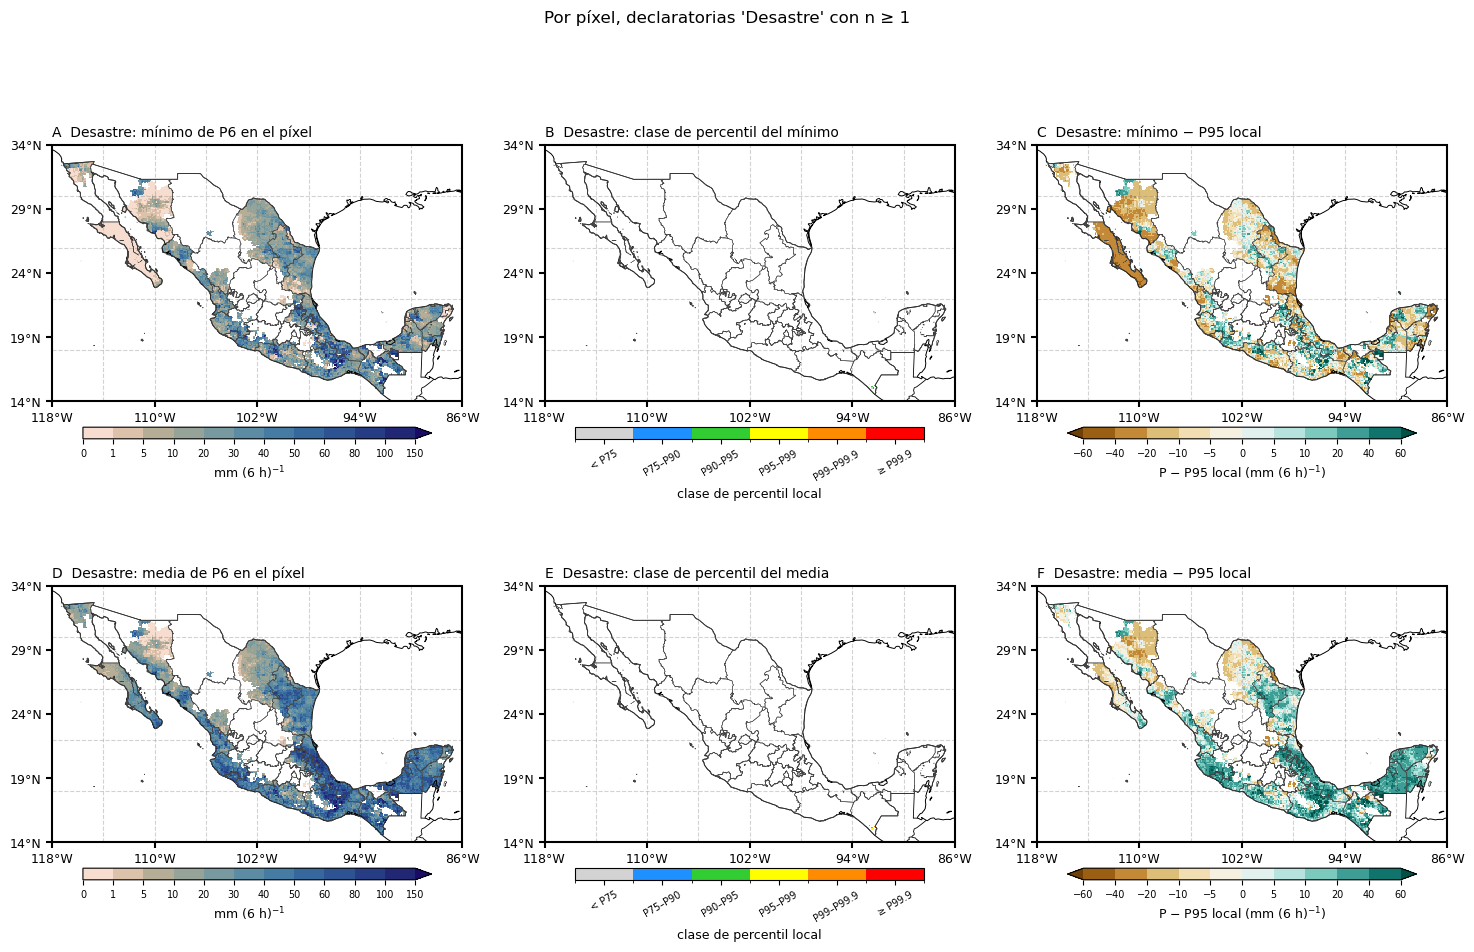

In [35]:
s = ps.sel(tipo=TIPO_MAPA)
ok = (s["n_decl"] >= N_MIN).values
k95 = LABS.index("P95")
pix = {}
for stat in ("min", "media"):
    p = np.where(ok, s[f"P_{stat}"].values, np.nan)
    pix[stat] = dict(P=p, C=pct_class(p, QPIX), R=pct_equiv(p, QPIX), D=p - QPIX[k95])

fig, axs = plt.subplots(2, 3, figsize=(18, 10.5), subplot_kw={"projection": PC})
for row, (stat, nombre) in enumerate([("min", "mínimo"), ("media", "media")]):
    for col, kind in enumerate("PCD"):
        ax = axs[row, col]
        pixel_map(ax, pix[stat][kind], kind)
        titulo = {"P": f"{nombre} de P6 en el píxel", "C": f"clase de percentil del {nombre}",
                  "D": f"{nombre} − P95 local"}[kind]
        finish_map(ax, f"{'ABCDEF'[3 * row + col]}  {TIPO_MAPA}: {titulo}")
        add_cbar(fig, ax, kind)
fig.suptitle(f"Por píxel, declaratorias '{TIPO_MAPA}' con n ≥ {N_MIN}", fontsize=12)
fig.savefig(FIG / f"fig_pixel_min_media_{TIPO_MAPA}.png", dpi=300, bbox_inches="tight")

# Fracción de píxeles en cada clase
pd.DataFrame({f"{n} (%)": pd.Series(pix[st]["C"][ok]).dropna().astype(int).value_counts(normalize=True)
              .reindex(range(6), fill_value=0).mul(100).set_axis(CLASS_LABELS)
              for st, n in (("min", "mínimo"), ("media", "media"))}).round(1)

## 5. Mapas por municipio

Por municipio, con las declaratorias del tipo elegido:

- **mínimo**: la declaratoria con menor $P_{\mathrm{evento}}$, con su clase y su $P - P_{95}$ evaluados en su propio píxel del máximo;
- **media**: media de $P_{\mathrm{evento}}$ (mm), mediana de las clases (ordinal) y media de $P_{\mathrm{evento}} - P_{95}$.

Los municipios con menos de `N_MIN` declaratorias se muestran en gris oscuro.

/tmp/ipykernel_8573/1519926016.py:40: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "P_media", "clase_mediana"]].head(20).round(1))


,CVEGEO,NOMGEO,NOM_ENT,n,P_min,clase_min,dif_min_P95,CT_min,t_min,P_media,clase_mediana
53,06007,Manzanillo,Colima,13,0.0,0.0,-31.1,EP022015,2015-06-07 00:00:00,87.7,4.0
904,21016,Aquixtla,Puebla,5,0.0,0.0,-18.4,AL072017,2017-08-09 00:00:00,43.2,3.0
1100,26019,Cananea,Sonora,1,0.0,0.0,-17.6,EP112007,2007-09-05 00:00:00,0.0,0.0
909,21205,Yehualtepec,Puebla,1,0.0,0.0,-23.0,AL072017,2017-08-09 00:00:00,0.0,0.0
1008,21007,Ahuatlán,Puebla,1,0.0,0.0,-24.1,AL072017,2017-08-09 00:00:00,0.0,0.0
960,21173,Teteles de Ávila Castillo,Puebla,4,0.0,0.0,-41.7,AL072017,2017-08-09 00:00:00,82.4,4.0
959,21017,Atempan,Puebla,5,0.0,0.0,-41.7,AL072017,2017-08-09 00:00:00,83.6,4.0
907,21211,Zaragoza,Puebla,4,0.0,0.0,-31.3,AL072017,2017-08-09 00:00:00,37.4,1.0
951,21208,Zacatlán,Puebla,5,0.0,0.0,-18.8,AL072017,2017-08-09 00:00:00,48.7,3.0
1065,26011,Bacoachi,Sonora,1,0.0,0.0,-15.0,EP112007,2007-09-05 18:00:00,0.0,0.0


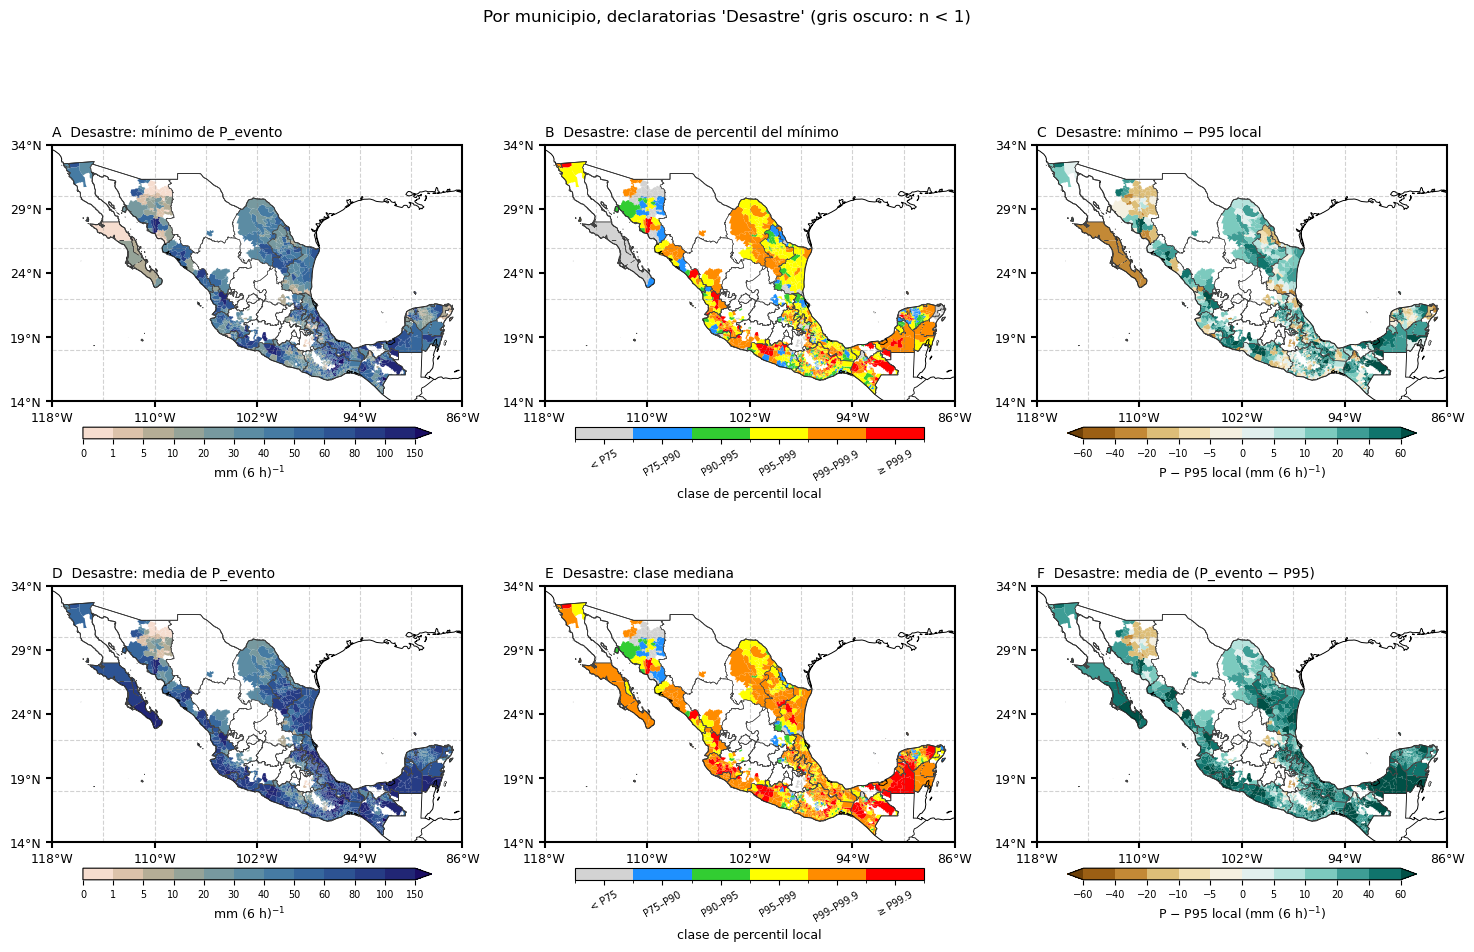

In [36]:
def municipal_stats(g: pd.DataFrame) -> pd.Series:
    i = g["P_evento"].idxmin()
    return pd.Series({
        "n": len(g),
        "P_min": g.loc[i, "P_evento"], "clase_min": g.loc[i, "clase"], "r_min": g.loc[i, "r_equiv"],
        "dif_min_P95": g.loc[i, "dif_P95"], "CT_min": g.loc[i, "CT_pico"], "t_min": g.loc[i, "t_pico"],
        "Identificador_min": g.loc[i, "Identificador"],
        "P_media": g["P_evento"].mean(), "P_mediana": g["P_evento"].median(),
        "clase_mediana": np.quantile(g["clase"].dropna(), 0.5, method="lower"),
        "dif_media_P95": g["dif_P95"].mean(),
    })


def tabla_municipal(tipo: str) -> pd.DataFrame:
    e = ev if tipo == "todas" else ev[ev["Tipo Declaratoria"].eq(tipo)]
    cols = ["P_evento", "clase", "r_equiv", "dif_P95", "CT_pico", "t_pico", "Identificador"]
    out = e.groupby("CVEGEO")[cols].apply(municipal_stats).reset_index()
    return out.assign(suficiente=out["n"] >= N_MIN)


mun_t = tabla_municipal(TIPO_MAPA)
gm = gdf_mun[["CVEGEO", "NOMGEO", "NOM_ENT", "geometry"]].merge(mun_t, on="CVEGEO")
suf, insuf = gm[gm["suficiente"]], gm[~gm["suficiente"]]

panels = [("P_min", "P", "mínimo de P_evento"), ("clase_min", "C", "clase de percentil del mínimo"),
          ("dif_min_P95", "D", "mínimo − P95 local"),
          ("P_media", "P", "media de P_evento"), ("clase_mediana", "C", "clase mediana"),
          ("dif_media_P95", "D", "media de (P_evento − P95)")]
fig, axs = plt.subplots(2, 3, figsize=(18, 10.5), subplot_kw={"projection": PC})
for n, (ax, (column, kind, titulo)) in enumerate(zip(axs.flat, panels)):
    mun_map(ax, suf, column, kind, insuf)
    finish_map(ax, f"{'ABCDEF'[n]}  {TIPO_MAPA}: {titulo}")
    add_cbar(fig, ax, kind)
fig.suptitle(f"Por municipio, declaratorias '{TIPO_MAPA}' (gris oscuro: n < {N_MIN})", fontsize=12)
fig.savefig(FIG / f"fig_municipio_min_media_{TIPO_MAPA}.png", dpi=300, bbox_inches="tight")

mun_t.to_csv(FIG / f"municipios_{TIPO_MAPA}.csv", index=False, float_format="%.2f")
(gm[gm["suficiente"]].drop(columns="geometry").sort_values("P_min")
 [["CVEGEO", "NOMGEO", "NOM_ENT", "n", "P_min", "clase_min", "dif_min_P95", "CT_min", "t_min",
   "P_media", "clase_mediana"]].head(20).round(1))

## 6. Intervalos de lluvia de 6 h asociados a declaratorias, para toma de decisiones

Tres métodos complementarios, con las declaratorias de `TIPO_INT` (por defecto Desastre, que se emite tras verificar daños). En todos, el **umbral inferior** se lee como: "el 90 % (o 75 %) de las declaratorias de este tipo ocurrió con al menos esta lluvia de 6 h". Es una caracterización empírica de lo que acompañó a las declaratorias, no una probabilidad de declaratoria dada la lluvia: para eso haría falta incluir también los eventos con lluvia intensa sin declaratoria.

**A. Empírico por municipio.** Con $n \ge$ `N_MIN_INT` declaratorias: cuantiles 10, 25 y 50 % de $P_{\mathrm{evento}}$ (Hyndman y Fan tipo 8, igual que los percentiles climatológicos) y la clase de percentil del cuantil 10 % de $r$.

**B. Incertidumbre de la mediana municipal (bootstrap).** Intervalo de confianza del 90 % de la mediana de $P_{\mathrm{evento}}$ por remuestreo (2000 réplicas). Con pocos casos el intervalo es ancho; su ancho indica cuánto confiar en el umbral del método A.

**C. Normalizado por percentil y llevado a todo el territorio.** Se agrupan las declaratorias de todo el país en términos de su percentil equivalente $r$, se toman sus cuantiles $r_{10}, r_{25}, r_{50}$, y se convierten a mm en cada píxel con $Q(r)$. Supone que el percentil local que acompaña a las declaratorias es espacialmente homogéneo; a cambio, da un umbral para píxeles y municipios sin suficientes declaratorias. Si $r_{10}$ queda por debajo de P75, el umbral está censurado y no se mapea.

Desastre: 280 municipios con n ≥ 5 (de 1482 con alguna declaratoria)


,CVEGEO,NOMGEO,NOM_ENT,n,P10,P25,P50,clase_r10,IC_mediana_inf,IC_mediana_sup
156,21017,Atempan,Puebla,5.0,0.0,58.9,100.1,0.0,0.0,128.5
154,21208,Zacatlán,Puebla,5.0,0.0,7.6,47.4,0.0,10.8,98.0
145,21016,Aquixtla,Puebla,5.0,0.0,12.9,22.9,0.0,0.0,87.4
144,21200,Xochiapulco,Puebla,5.0,0.4,24.5,63.5,0.0,0.4,144.3
147,21167,Tepetzintla,Puebla,5.0,0.6,2.3,17.4,0.0,0.6,84.1
5,06007,Manzanillo,Colima,13.0,0.7,38.4,81.9,0.0,56.3,120.3
161,23001,Cozumel,Quintana Roo,5.0,0.8,1.1,18.2,0.0,0.8,41.8
186,30052,Cuichapa,Veracruz de Ignacio de la Llave,5.0,0.8,22.0,33.4,0.0,0.8,49.6
142,21202,Xochitlán de Vicente Suárez,Puebla,6.0,1.7,26.5,59.5,0.0,27.0,104.9
160,23005,Benito Juárez,Quintana Roo,5.0,1.9,13.9,33.5,0.0,1.9,130.4


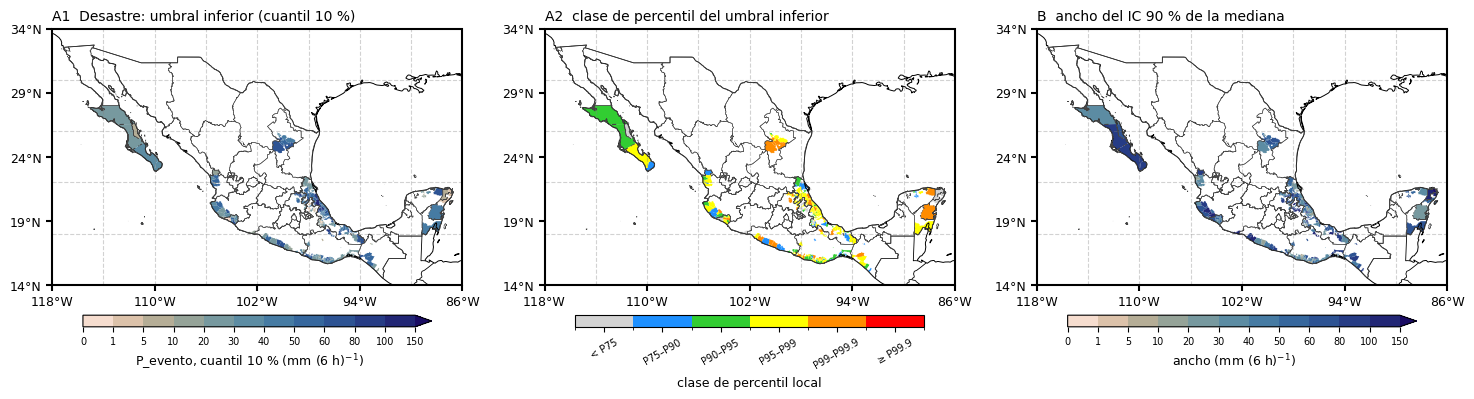

In [37]:
e_int = ev[ev["Tipo Declaratoria"].eq(TIPO_INT)]
rng = np.random.default_rng(42)
B_BOOT, ALPHA = 2000, 0.10


def intervalos(g: pd.DataFrame) -> pd.Series:
    x = g["P_evento"].to_numpy()
    q10, q25, q50 = np.quantile(x, [0.10, 0.25, 0.50], method="median_unbiased")
    r10 = np.quantile(g["r_ord"].dropna().to_numpy(), 0.10, method="lower")
    med = np.median(x[rng.integers(0, x.size, (B_BOOT, x.size))], axis=1)       # método B
    lo, hi = np.quantile(med, [ALPHA / 2, 1 - ALPHA / 2])
    clase10 = 0 if r10 < LEVELS[0] else int(np.sum(r10 >= LEVELS))
    return pd.Series({"n": x.size, "P10": q10, "P25": q25, "P50": q50, "clase_r10": clase10,
                      "IC_mediana_inf": lo, "IC_mediana_sup": hi, "IC_ancho": hi - lo})


counts = e_int.groupby("CVEGEO").size()
gA = e_int[e_int["CVEGEO"].isin(counts[counts >= N_MIN_INT].index)]
intA = gA.groupby("CVEGEO")[["P_evento", "r_ord"]].apply(intervalos).reset_index()
intA = gdf_mun[["CVEGEO", "NOMGEO", "NOM_ENT"]].merge(intA, on="CVEGEO")
intA.to_csv(FIG / f"intervalos_municipio_{TIPO_INT}.csv", index=False, float_format="%.2f")
print(f"{TIPO_INT}: {len(intA)} municipios con n ≥ {N_MIN_INT} "
      f"(de {e_int['CVEGEO'].nunique()} con alguna declaratoria)")

gA_map = gdf_mun[["CVEGEO", "geometry"]].merge(intA, on="CVEGEO")
fig, axs = plt.subplots(1, 3, figsize=(18, 5.6), subplot_kw={"projection": PC})
mun_map(axs[0], gA_map, "P10", "P")
finish_map(axs[0], f"A1  {TIPO_INT}: umbral inferior (cuantil 10 %)")
add_cbar(fig, axs[0], "P", "P_evento, cuantil 10 % (mm (6 h)$^{-1}$)")
mun_map(axs[1], gA_map, "clase_r10", "C")
finish_map(axs[1], "A2  clase de percentil del umbral inferior")
add_cbar(fig, axs[1], "C")
mun_map(axs[2], gA_map, "IC_ancho", "P")
finish_map(axs[2], f"B  ancho del IC {100 * (1 - ALPHA):.0f} % de la mediana")
add_cbar(fig, axs[2], "P", "ancho (mm (6 h)$^{-1}$)")
fig.savefig(FIG / f"fig_intervalos_municipio_{TIPO_INT}.png", dpi=300, bbox_inches="tight")

intA.sort_values("P10")[["CVEGEO", "NOMGEO", "NOM_ENT", "n", "P10", "P25", "P50", "clase_r10",
                          "IC_mediana_inf", "IC_mediana_sup"]].head(20).round(1)

{'r10': 91.5, 'r25': 96.7, 'r50': 99.2}


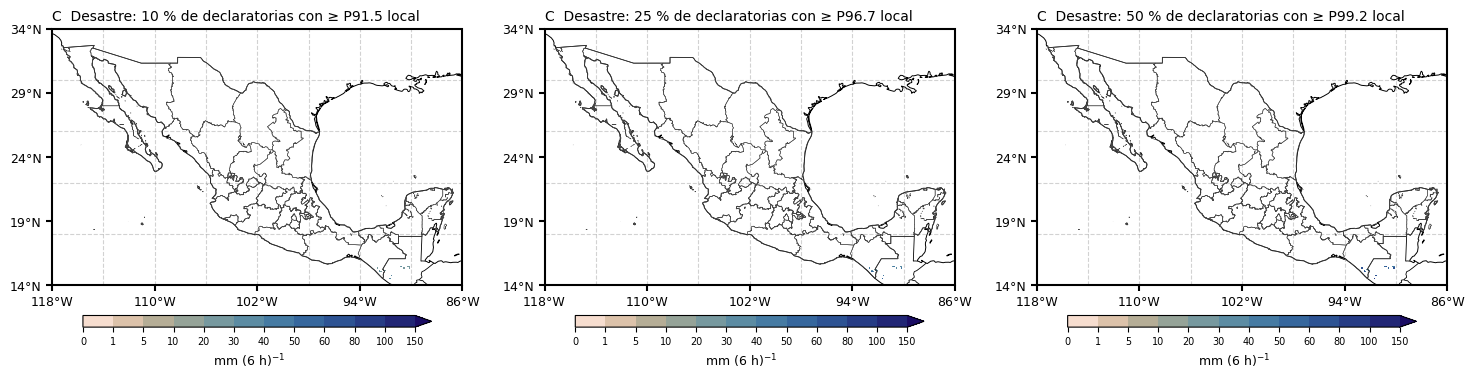

In [38]:
# Método C: cuantiles nacionales del percentil equivalente, llevados a mm en cada píxel
r_q = {p: float(np.quantile(e_int["r_ord"].dropna(), p, method="lower")) for p in (0.10, 0.25, 0.50)}
print({f"r{int(100 * p)}": ("< P75" if r < LEVELS[0] else round(r, 1)) for p, r in r_q.items()})

fig, axs = plt.subplots(1, 3, figsize=(18, 5.6), subplot_kw={"projection": PC})
cobertura = np.isfinite(QPIX).all(axis=0)
for ax, (p, r) in zip(axs, r_q.items()):
    mm = pct_to_mm(r, QPIX) if r >= LEVELS[0] else np.full(QPIX[0].shape, np.nan)
    pixel_map(ax, np.where(cobertura, mm, np.nan), "P")
    etiqueta = "< P75 (censurado)" if r < LEVELS[0] else f"P{r:.1f} local"
    finish_map(ax, f"C  {TIPO_INT}: {int(100 * p)} % de declaratorias con ≥ {etiqueta}")
    add_cbar(fig, ax, "P")
fig.savefig(FIG / f"fig_umbral_percentil_nacional_{TIPO_INT}.png", dpi=300, bbox_inches="tight")

In [39]:
# Comparación de métodos A y C en los municipios con intervalo empírico
mm_c10 = pct_to_mm(r_q[0.10], Q_EV) if r_q[0.10] >= LEVELS[0] else np.full(len(ev), np.nan)
c10_mun = ev.assign(P10_C=mm_c10)[ev["Tipo Declaratoria"].eq(TIPO_INT)] \
            .groupby("CVEGEO")["P10_C"].median().rename("P10_metodoC")
comp = intA.set_index("CVEGEO")[["NOMGEO", "NOM_ENT", "n", "P10"]].join(c10_mun)
comp["A − C"] = comp["P10"] - comp["P10_metodoC"]
print(f"A − C (mm): mediana {comp['A − C'].median():.1f} | P10–P90 "
      f"[{comp['A − C'].quantile(0.1):.1f}, {comp['A − C'].quantile(0.9):.1f}]")
comp.sort_values("A − C").round(1).head(15)

A − C (mm): mediana 9.6 | P10–P90 [-15.8, 37.6]


,NOMGEO,NOM_ENT,n,P10,P10_metodoC,A − C
CVEGEO,,,,,,
21017,Atempan,Puebla,5.0,0.0,30.3,-30.3
16052,Lázaro Cárdenas,Michoacán de Ocampo,5.0,12.6,41.5,-28.9
21207,Zacapoaxtla,Puebla,6.0,4.9,32.3,-27.5
20248,San Mateo del Mar,Oaxaca,5.0,11.7,38.8,-27.0
06007,Manzanillo,Colima,13.0,0.7,27.2,-26.5
03009,Loreto,Baja California Sur,15.0,6.2,31.5,-25.3
21200,Xochiapulco,Puebla,5.0,0.4,25.6,-25.2
21197,Xicotepec,Puebla,5.0,2.2,26.8,-24.6
23003,Isla Mujeres,Quintana Roo,5.0,3.2,27.5,-24.3


## 7. Consultas

In [40]:
# Un municipio: sus declaratorias, lluvia, percentil equivalente y clase
CVEGEO = mun_t.sort_values("P_min")["CVEGEO"].iloc[0]     # cambiar por la clave (5 dígitos)
print(gdf_mun.loc[gdf_mun["CVEGEO"].eq(CVEGEO), ["NOMGEO", "NOM_ENT"]].to_string(index=False))
e = ev[ev["CVEGEO"].eq(CVEGEO)].sort_values("fecha_inicio").assign(
    clase_txt=lambda d: d["clase"].map(dict(enumerate(CLASS_LABELS))))
e[["Identificador", "Tipo Declaratoria", "Observaciones", "fecha_inicio", "fecha_fin", "CT_pico", "t_pico",
   "dist_pico_km", "P_evento", "P_evento_areal", "P95_pixel_max", "r_equiv", "clase_txt"]].round(1)

    NOMGEO NOM_ENT
Manzanillo  Colima


/tmp/ipykernel_8573/1041766654.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "dist_pico_km", "P_evento", "P_evento_areal", "P95_pixel_max", "r_equiv", "clase_txt"]].round(1)


,Identificador,Tipo Declaratoria,Observaciones,fecha_inicio,fecha_fin,CT_pico,t_pico,dist_pico_km,P_evento,P_evento_areal,P95_pixel_max,r_equiv,clase_txt
6779,26326,Emergencia,Depresión tropical Norman con posibles lluvias...,2000-09-19,2000-09-22,EP162000,2000-09-21 18:00:00,159.7,68.6,40.0,42.0,97.7,P95–P99
6880,26339,Desastre,Lluvias atípicas e impredecibles y por inundac...,2000-09-21,2000-09-22,EP162000,2000-09-21 18:00:00,159.7,68.6,39.1,42.0,97.7,P95–P99
92,1537,Desastre,"Huracan ""Kena""",2002-10-25,2002-10-25,EP142002,2002-10-25 12:00:00,271.5,79.7,36.4,42.0,98.8,P95–P99
2235,7762,Desastre,"Huracan ""Lane""",2006-09-14,2006-09-15,EP132006,2006-09-15 00:00:00,146.3,56.3,38.7,37.2,97.1,P95–P99
2266,7923,Emergencia,"Huracan ""Lane""",2006-09-14,2006-09-15,EP132006,2006-09-15 00:00:00,146.3,56.3,38.7,37.2,97.1,P95–P99
4641,15025,Desastre,Huracan Jova,2011-10-12,2011-10-12,EP102011,2011-10-12 12:00:00,175.8,215.8,154.1,26.1,99.9,≥ P99.9
4651,15036,Emergencia,Huracan Jova,2011-10-12,2011-10-12,EP102011,2011-10-12 12:00:00,175.8,215.8,154.1,26.1,99.9,≥ P99.9
4950,16572,Contingencia Climatológica,Huracan Jova Desastre Sagarpa,2011-10-12,2011-10-12,EP102011,2011-10-12 12:00:00,175.8,215.8,154.1,26.1,99.9,≥ P99.9
5711,18306,Emergencia,Tormenta tropical Manuel,2013-09-15,2013-09-17,EP132013,2013-09-16 18:00:00,261.4,81.9,49.7,35.7,99.1,P99–P99.9
5596,18169,Desastre,Tormenta tropical Manuel,2013-09-16,2013-09-17,EP132013,2013-09-16 18:00:00,261.4,81.9,49.7,35.7,99.1,P99–P99.9


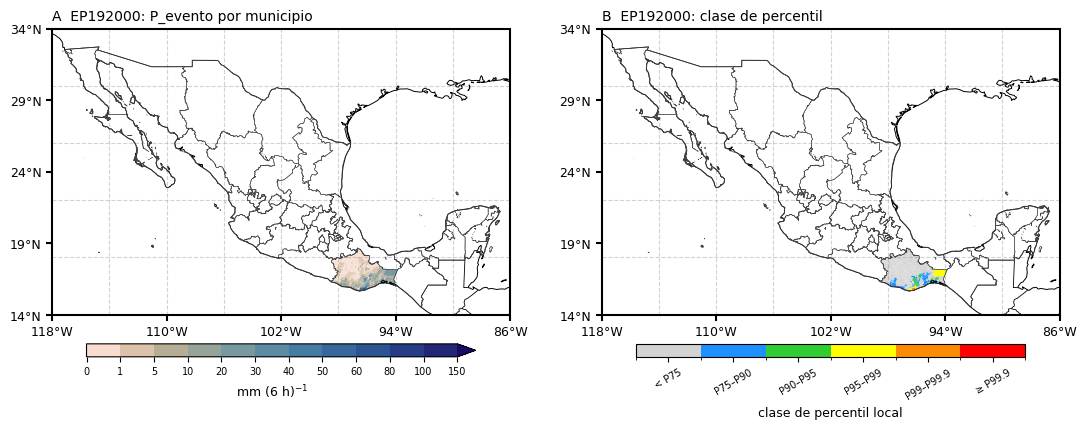

In [41]:
# Un ciclón: municipios con declaratoria coloreados por P_evento y por clase de percentil
cic = ev.groupby("CT_pico").size().sort_values()
CT = cic.index[-1]                                            # cambiar, p. ej. "AL032020"
e = ev[ev["CT_pico"].eq(CT)].sort_values("P_evento").groupby("CVEGEO").tail(1)
m = gdf_mun[["CVEGEO", "geometry"]].merge(e[["CVEGEO", "P_evento", "clase"]], on="CVEGEO")

fig, axs = plt.subplots(1, 2, figsize=(13, 5.4), subplot_kw={"projection": PC})
mun_map(axs[0], m, "P_evento", "P")
finish_map(axs[0], f"A  {CT}: P_evento por municipio")
add_cbar(fig, axs[0], "P")
mun_map(axs[1], m, "clase", "C")
finish_map(axs[1], f"B  {CT}: clase de percentil")
add_cbar(fig, axs[1], "C")
fig.savefig(FIG / f"fig_ciclon_{CT}.png", dpi=300, bbox_inches="tight")